# Week 7 - HealthConnect Model Testing, Error Analysis & Refinement
**AnalystLab Africa Experience Lab - Data Science Track**

This notebook continues the exact Week 6 HealthConnect Rwanda work. It does **not** start a new project or invent an attendance/no-show target. AnalystLab Africa clarified that Week 7 should use the same Week 6 dataset. Because the supplied Rwanda appointment data does not contain an attendance/no-show outcome, this notebook tests and refines the genuine Week 6 classification component: **hospital admission prediction**.

The Week 7 progression is: **Week 6 Output -> Test -> Identify Issues -> Refine -> Re-test -> Validate -> Document -> Prepare for Week 8.**

## 1. Week 6 -> Week 7 transition

- **Main Week 6 output:** integrated HealthConnect Rwanda Data Science project with admission prediction, satisfaction prediction, forecasting and clustering.
- **Candidate classification model:** Gradient Boosting for hospital admission.
- **Week 6 weakness:** ROC-AUC was approximately 0.497, indicating near-random discrimination.
- **Week 7 testing focus:** reproduce the candidate, evaluate it under a stricter train/validation/test protocol, analyse false positives/false negatives, test segment stability, evaluate cross-validation, apply a justified refinement, retest it, and decide whether any model is suitable for operational use.
- **Attendance/no-show limitation:** no attendance/no-show/cancellation outcome is present in the supplied Week 6 Rwanda appointment data. This limitation is documented rather than filled with a fabricated proxy.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt, warnings, zipfile, json
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score, recall_score,
                             f1_score, balanced_accuracy_score, confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.inspection import permutation_importance
warnings.filterwarnings('ignore')
SEED=42
print('Libraries loaded. Random seed:', SEED)

Libraries loaded. Random seed: 42


## 2. Google Drive setup and exact source discovery
The original Week 6 package is preserved unchanged. In Colab, the notebook searches recursively under `/content/drive/MyDrive/Analyst Lab Africa` for the exact Week 6 final ZIP or the exact integrated dataset. It refuses ambiguous duplicate matches rather than silently choosing one.

In [2]:
if Path('/content').exists():
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT=Path('/content/drive/MyDrive/Analyst Lab Africa')
    if not DRIVE_ROOT.exists():
        raise FileNotFoundError(f'Drive project root not found: {DRIVE_ROOT}')
    PROJECT_DIR=DRIVE_ROOT/'Week7_DataScience_HealthConnect_TakudzwaGumbo'
else:
    DRIVE_ROOT=Path('/mnt/data')
    PROJECT_DIR=Path('/mnt/data/week7_notebook_outputs')
PROJECT_DIR.mkdir(parents=True,exist_ok=True)
for name in ['Evidence','Visualizations','Models']:
    (PROJECT_DIR/name).mkdir(exist_ok=True)
print('Working output folder:',PROJECT_DIR)

def find_exact(filename, root):
    matches=list(root.rglob(filename))
    if len(matches)==0: return None
    if len(matches)>1:
        print('Multiple copies found:')
        for m in matches: print(' -',m)
        raise RuntimeError(f'Resolve duplicate copies of {filename} before proceeding.')
    return matches[0]

if Path('/content').exists():
    integrated_path=find_exact('Integrated_Healthcare_Dataset.csv',DRIVE_ROOT)
    zip_path=find_exact('Week6_DataScience_HealthConnect_TakudzwaGumbo_FINAL.zip',DRIVE_ROOT)
    if integrated_path is None and zip_path is None:
        raise FileNotFoundError('Could not find either the Week 6 final ZIP or Integrated_Healthcare_Dataset.csv under the Drive root.')
    if integrated_path is None:
        extract_dir=PROJECT_DIR/'_week6_working_copy'
        extract_dir.mkdir(exist_ok=True)
        with zipfile.ZipFile(zip_path) as z:
            member='Data/Integrated/Integrated_Healthcare_Dataset.csv'
            z.extract(member,extract_dir)
        integrated_path=extract_dir/member
else:
    integrated_path=Path('/mnt/data/w6src/Data/Integrated/Integrated_Healthcare_Dataset.csv')

print('Selected Week 6 integrated dataset:',integrated_path)
df=pd.read_csv(integrated_path)
print('Shape:',df.shape)
print('Admission rate:',round(df.Admitted.mean(),4))

Working output folder: /mnt/data/week7_notebook_outputs
Selected Week 6 integrated dataset: /mnt/data/w6src/Data/Integrated/Integrated_Healthcare_Dataset.csv
Shape: (5000, 51)
Admission rate: 0.1172


## 3. Resource and target audit
This check confirms the exact modelling target that is available and explicitly tests whether an appointment attendance/no-show outcome exists.

In [3]:
attendance_terms=['attendance','attended','no_show','noshow','no-show','cancelled','canceled','appointment_status']
attendance_matches=[c for c in df.columns if any(t in c.lower() for t in attendance_terms)]
print('Attendance/no-show-like columns:',attendance_matches)
print('Available admission target:', 'Admitted' in df.columns)
print(df['Admitted'].value_counts().rename('count'))
print('Positive rate:',df.Admitted.mean())
if attendance_matches:
    print('Review these fields before using them as an attendance target.')
else:
    print('LIMITATION CONFIRMED: no attendance/no-show outcome is available; it will not be fabricated.')

Attendance/no-show-like columns: []
Available admission target: True
Admitted
0    4414
1     586
Name: count, dtype: int64
Positive rate: 0.1172
LIMITATION CONFIRMED: no attendance/no-show outcome is available; it will not be fabricated.


## 4. Week 6 candidate reproduction
The exact Week 6 feature set, preprocessing, 80/20 stratified split and three-model comparison are reproduced first. This establishes continuity before Week 7 testing.

In [4]:
full_features=['Age','Gender','MaritalStatus','Education','BloodGroup','BMI','HasChronicCondition','VisitType','FacilityID','DepartmentID','Diagnosis','Severity']
num=['Age','BMI','HasChronicCondition']
cat=[c for c in full_features if c not in num]

def make_pre(features):
    nums=[c for c in ['Age','BMI','HasChronicCondition'] if c in features]
    cats=[c for c in features if c not in nums]
    return ColumnTransformer([
        ('num',Pipeline([('imp',SimpleImputer(strategy='median')),('sc',StandardScaler())]),nums),
        ('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('ohe',OneHotEncoder(handle_unknown='ignore'))]),cats)])

def metric_row(model,split,y_true,prob,thr=.5):
    pred=(prob>=thr).astype(int); tn,fp,fn,tp=confusion_matrix(y_true,pred,labels=[0,1]).ravel()
    return {'Model':model,'Split':split,'Threshold':thr,'ROC_AUC':roc_auc_score(y_true,prob),'PR_AUC':average_precision_score(y_true,prob),
            'Accuracy':accuracy_score(y_true,pred),'Balanced_Accuracy':balanced_accuracy_score(y_true,pred),'Precision':precision_score(y_true,pred,zero_division=0),
            'Recall':recall_score(y_true,pred,zero_division=0),'F1':f1_score(y_true,pred,zero_division=0),'TN':tn,'FP':fp,'FN':fn,'TP':tp}

X=df[full_features]; y=df.Admitted.astype(int)
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=.2,stratify=y,random_state=SEED)
week6_models={
'Logistic Regression':LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED),
'Random Forest':RandomForestClassifier(n_estimators=250,max_depth=10,min_samples_leaf=5,class_weight='balanced',random_state=SEED,n_jobs=-1),
'Gradient Boosting':GradientBoostingClassifier(random_state=SEED)}
rows=[]
for name,m in week6_models.items():
    p=Pipeline([('pre',make_pre(full_features)),('model',m)]); p.fit(X_dev,y_dev); prob=p.predict_proba(X_test)[:,1]; rows.append(metric_row(name,'test',y_test,prob,.5))
week6_reproduction=pd.DataFrame(rows).sort_values('ROC_AUC',ascending=False)
display(week6_reproduction.round(4))
week6_reproduction.to_csv(PROJECT_DIR/'Evidence/week6_candidate_reproduction.csv',index=False)

,Model,Split,Threshold,ROC_AUC,PR_AUC,Accuracy,Balanced_Accuracy,Precision,Recall,F1,TN,FP,FN,TP
2,Gradient Boosting,test,0.5,0.4967,0.1186,0.881,0.4989,0.0000,0.0000,0.0000,881,2,117,0
0,Logistic Regression,test,0.5,0.4959,0.1176,0.532,0.4829,0.1091,0.4188,0.1731,483,400,68,49
1,Random Forest,test,0.5,0.4829,0.1106,0.728,0.4864,0.1026,0.1709,0.1282,708,175,97,20


**Interpretation:** The Week 6 candidate is Gradient Boosting only because it had the highest ROC-AUC among the tested models. Its ROC-AUC remains approximately 0.497, so “best candidate” does not mean “good model.”

## 5. Week 7 testing protocol
To prevent test-set tuning, the original Week 6 development portion is split into **training (60%)** and **validation (20%)**, while the original Week 6 test set remains the final **20% holdout**. The validation set is used for refinement decisions; the test set is used for final comparison.

In [5]:
X_train,X_val,y_train,y_val=train_test_split(X_dev,y_dev,test_size=.25,stratify=y_dev,random_state=SEED)
print('Train:',len(X_train),'Validation:',len(X_val),'Test:',len(X_test))
print('Positive rates:',y_train.mean(),y_val.mean(),y_test.mean())

Train: 3000 Validation: 1000 Test: 1000
Positive rates: 0.11733333333333333 0.117 0.117


## 6. Candidate testing and baseline comparison

In [6]:
models={
'Dummy Prior':DummyClassifier(strategy='prior'),
'Logistic Regression':LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED),
'Random Forest':RandomForestClassifier(n_estimators=250,max_depth=10,min_samples_leaf=5,class_weight='balanced',random_state=SEED,n_jobs=-1),
'Week 6 Candidate - Gradient Boosting':GradientBoostingClassifier(random_state=SEED)}
fitted={}; rows=[]
for name,m in models.items():
    p=Pipeline([('pre',make_pre(full_features)),('model',m)]); p.fit(X_train,y_train); fitted[name]=p
    for split,Xs,ys in [('validation',X_val,y_val),('test',X_test,y_test)]:
        rows.append(metric_row(name,split,ys,p.predict_proba(Xs)[:,1],.5))
week7_results=pd.DataFrame(rows)
display(week7_results.round(4))
week7_results.to_csv(PROJECT_DIR/'Evidence/week7_model_test_results.csv',index=False)

,Model,Split,Threshold,ROC_AUC,PR_AUC,Accuracy,Balanced_Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Dummy Prior,validation,0.5,0.5000,0.1170,0.883,0.5000,0.0000,0.0000,0.0000,883,0,117,0
1,Dummy Prior,test,0.5,0.5000,0.1170,0.883,0.5000,0.0000,0.0000,0.0000,883,0,117,0
2,Logistic Regression,validation,0.5,0.4932,0.1118,0.595,0.4815,0.1066,0.3333,0.1615,556,327,78,39
3,Logistic Regression,test,0.5,0.5107,0.1207,0.565,0.5053,0.1196,0.4274,0.1869,515,368,67,50
4,Random Forest,validation,0.5,0.4579,0.1067,0.785,0.4964,0.1111,0.1197,0.1152,771,112,103,14
5,Random Forest,test,0.5,0.4952,0.1150,0.771,0.4959,0.1111,0.1368,0.1226,755,128,101,16
6,Week 6 Candidate - Gradient Boosting,validation,0.5,0.5113,0.1353,0.880,0.4983,0.0000,0.0000,0.0000,880,3,117,0
7,Week 6 Candidate - Gradient Boosting,test,0.5,0.4917,0.1244,0.883,0.5037,0.5000,0.0085,0.0168,882,1,116,1


## 7. Cross-validation / generalisation test
Five-fold stratified cross-validation is run only on the Week 7 development data. This tests whether apparent performance is stable rather than dependent on one split.

In [7]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
cv_rows=[]
for name in ['Logistic Regression','Week 6 Candidate - Gradient Boosting']:
    p=Pipeline([('pre',make_pre(full_features)),('model',models[name])])
    sc=cross_validate(p,X_dev,y_dev,cv=cv,scoring={'roc':'roc_auc','pr':'average_precision','bal':'balanced_accuracy','rec':'recall','prec':'precision','f1':'f1'},n_jobs=-1)
    for metric,key in [('ROC_AUC','test_roc'),('PR_AUC','test_pr'),('Balanced_Accuracy','test_bal'),('Recall','test_rec'),('Precision','test_prec'),('F1','test_f1')]:
        cv_rows.append([name,metric,np.mean(sc[key]),np.std(sc[key])])
cv_results=pd.DataFrame(cv_rows,columns=['Model','Metric','Mean','Std'])
display(cv_results.round(4))
cv_results.to_csv(PROJECT_DIR/'Evidence/cross_validation_results.csv',index=False)

,Model,Metric,Mean,Std
0,Logistic Regression,ROC_AUC,0.5054,0.0171
1,Logistic Regression,PR_AUC,0.1197,0.0085
2,Logistic Regression,Balanced_Accuracy,0.4997,0.0215
3,Logistic Regression,Recall,0.4009,0.0442
4,Logistic Regression,Precision,0.1170,0.0112
5,Logistic Regression,F1,0.1811,0.0177
6,Week 6 Candidate - Gradient Boosting,ROC_AUC,0.4811,0.0205
7,Week 6 Candidate - Gradient Boosting,PR_AUC,0.1155,0.0065
8,Week 6 Candidate - Gradient Boosting,Balanced_Accuracy,0.4966,0.0019
9,Week 6 Candidate - Gradient Boosting,Recall,0.0000,0.0000


## 8. Error analysis: false positives and false negatives

Confusion matrix:
[[882   1]
 [116   1]]


ErrorType
True Negative     882
False Negative    116
True Positive       1
False Positive      1
Name: count, dtype: int64

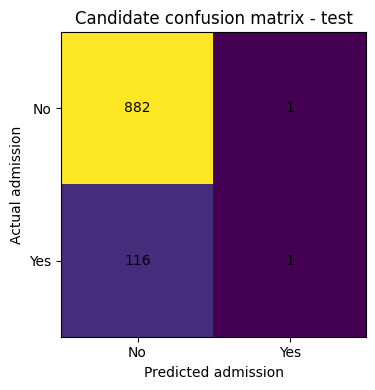

In [8]:
cand=fitted['Week 6 Candidate - Gradient Boosting']
cand_prob=cand.predict_proba(X_test)[:,1]; cand_pred=(cand_prob>=.5).astype(int)
cm=confusion_matrix(y_test,cand_pred)
print('Confusion matrix:'); print(cm)
error_table=df.loc[X_test.index,['Age','Gender','VisitType','FacilityID','DepartmentID','Diagnosis','Severity','Admitted']].copy()
error_table['Predicted']=cand_pred; error_table['Probability']=cand_prob
error_table['ErrorType']=np.select([(error_table.Admitted==1)&(error_table.Predicted==0),(error_table.Admitted==0)&(error_table.Predicted==1),(error_table.Admitted==1)&(error_table.Predicted==1)],['False Negative','False Positive','True Positive'],'True Negative')
display(error_table.ErrorType.value_counts())
error_table.to_csv(PROJECT_DIR/'Evidence/error_analysis_anonymised.csv',index=False)
fig,ax=plt.subplots(figsize=(5,4)); ax.imshow(cm); ax.set_xticks([0,1]); ax.set_yticks([0,1]); ax.set_xticklabels(['No','Yes']); ax.set_yticklabels(['No','Yes']); ax.set_xlabel('Predicted admission'); ax.set_ylabel('Actual admission'); ax.set_title('Candidate confusion matrix - test')
for i in range(2):
    for j in range(2): ax.text(j,i,str(cm[i,j]),ha='center',va='center')
plt.tight_layout(); plt.show()

**Finding:** At the default 0.50 threshold, the candidate predicts almost all patients as not admitted. High accuracy is therefore misleading because the positive class is only about 11.7%. ROC-AUC, PR-AUC, balanced accuracy, recall and the confusion matrix are more informative.

## 9. Segment performance

In [9]:
ctx=df.loc[X_test.index].copy(); ctx['Probability']=cand_prob; ctx['Predicted']=cand_pred
seg_rows=[]
for seg in ['Gender','VisitType','Severity','AgeGroup']:
    for level,g in ctx.groupby(seg,dropna=False):
        if len(g)>=30 and g.Admitted.nunique()==2:
            r=metric_row('Candidate',f'{seg}={level}',g.Admitted,g.Probability,.5); r.update({'Segment':seg,'Level':str(level),'N':len(g),'Positive_Rate':g.Admitted.mean()}); seg_rows.append(r)
segment_results=pd.DataFrame(seg_rows)
display(segment_results[['Segment','Level','N','Positive_Rate','ROC_AUC','PR_AUC','Recall','F1']].round(4))
segment_results.to_csv(PROJECT_DIR/'Evidence/segment_performance.csv',index=False)

,Segment,Level,N,Positive_Rate,ROC_AUC,PR_AUC,Recall,F1
0,Gender,Female,486,0.0988,0.5099,0.0993,0.0000,0.0000
1,Gender,Male,514,0.1342,0.4686,0.1494,0.0145,0.0282
2,VisitType,Consultation,354,0.1186,0.5352,0.1604,0.0000,0.0000
3,VisitType,Emergency,313,0.1342,0.4520,0.1167,0.0000,0.0000
4,VisitType,Follow-up,333,0.0991,0.4899,0.1526,0.0303,0.0588
5,Severity,Mild,357,0.1345,0.4450,0.1240,0.0000,0.0000
6,Severity,Moderate,322,0.0870,0.5221,0.1083,0.0357,0.0667
7,Severity,Severe,321,0.1277,0.5257,0.1660,0.0000,0.0000
8,AgeGroup,0-17,179,0.0950,0.5147,0.1231,0.0000,0.0000
9,AgeGroup,18-34,169,0.1538,0.4808,0.1471,0.0000,0.0000


## 10. Feature review / modelling weakness

In [10]:
perm=permutation_importance(cand,X_val,y_val,n_repeats=15,random_state=SEED,scoring='roc_auc',n_jobs=-1)
importance=pd.DataFrame({'Feature':full_features,'Importance_Mean':perm.importances_mean,'Importance_Std':perm.importances_std}).sort_values('Importance_Mean',ascending=False)
display(importance.round(4))
importance.to_csv(PROJECT_DIR/'Evidence/week7_candidate_permutation_importance.csv',index=False)

,Feature,Importance_Mean,Importance_Std
9,DepartmentID,0.0150,0.0129
5,BMI,0.0124,0.0114
7,VisitType,0.0063,0.0029
1,Gender,0.0058,0.0062
3,Education,0.0048,0.0044
6,HasChronicCondition,0.0012,0.0029
11,Severity,0.0002,0.0004
0,Age,-0.0002,0.0052
2,MaritalStatus,-0.0007,0.0037
4,BloodGroup,-0.0031,0.0122


The importance results are small and unstable, which is consistent with the near-chance model discrimination. High-cardinality facility/department identifiers are therefore tested as removable noise rather than assumed to be useful predictors.

## 11. Evidence-based refinement
A simpler comparator is tested: **balanced Logistic Regression without FacilityID and DepartmentID**. This reduces dependence on high-cardinality identifiers and is easier to interpret. The classification threshold is selected on the validation set by balanced accuracy; the final test set is not used to choose it.

In [11]:
ref_features=['Age','Gender','MaritalStatus','Education','BloodGroup','BMI','HasChronicCondition','VisitType','Diagnosis','Severity']
ref=Pipeline([('pre',make_pre(ref_features)),('model',LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED))])
ref.fit(X_train[ref_features],y_train)
val_prob=ref.predict_proba(X_val[ref_features])[:,1]
search=[]
for t in np.linspace(.05,.95,181):
    pred=(val_prob>=t).astype(int); search.append((balanced_accuracy_score(y_val,pred),f1_score(y_val,pred,zero_division=0),t))
best=max(search,key=lambda z:(z[0],z[1],-abs(z[2]-.5))); threshold=float(best[2])
print('Validation-selected threshold:',threshold)
val_row=metric_row('Refined comparator','validation',y_val,val_prob,threshold)
test_prob=ref.predict_proba(X_test[ref_features])[:,1]; test_row=metric_row('Refined comparator','test',y_test,test_prob,threshold)
display(pd.DataFrame([val_row,test_row]).round(4))

Validation-selected threshold: 0.4149999999999999


,Model,Split,Threshold,ROC_AUC,PR_AUC,Accuracy,Balanced_Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Refined comparator,validation,0.415,0.4875,0.1119,0.253,0.5288,0.1241,0.8889,0.2178,149,734,13,104
1,Refined comparator,test,0.415,0.5420,0.1303,0.237,0.5086,0.1191,0.8632,0.2093,136,747,16,101


## 12. Re-test the refinement with cross-validation

In [12]:
p=Pipeline([('pre',make_pre(ref_features)),('model',LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED))])
sc=cross_validate(p,X_dev[ref_features],y_dev,cv=cv,scoring={'roc':'roc_auc','pr':'average_precision','bal':'balanced_accuracy','rec':'recall','prec':'precision','f1':'f1'},n_jobs=-1)
ref_cv=pd.DataFrame({'Metric':['ROC_AUC','PR_AUC','Balanced_Accuracy','Recall','Precision','F1'],
'Mean':[sc['test_roc'].mean(),sc['test_pr'].mean(),sc['test_bal'].mean(),sc['test_rec'].mean(),sc['test_prec'].mean(),sc['test_f1'].mean()],
'Std':[sc['test_roc'].std(),sc['test_pr'].std(),sc['test_bal'].std(),sc['test_rec'].std(),sc['test_prec'].std(),sc['test_f1'].std()]})
display(ref_cv.round(4))
ref_cv.to_csv(PROJECT_DIR/'Evidence/refined_cross_validation_results.csv',index=False)

,Metric,Mean,Std
0,ROC_AUC,0.4875,0.0257
1,PR_AUC,0.1166,0.0061
2,Balanced_Accuracy,0.5073,0.0166
3,Recall,0.4905,0.0327
4,Precision,0.1204,0.0069
5,F1,0.1933,0.0112


## 13. Baseline vs candidate vs refined decision

The refinement improves ROC-AUC on one final holdout split, but this improvement is **not supported by cross-validation**, where discrimination remains around chance. The validation-selected threshold increases recall at the cost of very low precision and many false positives. Therefore the refinement is **rejected as a validated operational improvement**.

**Final model suitability decision:** no tested model is suitable for operational HealthConnect admission prediction on the supplied feature set. The correct Week 7 outcome is a validated negative result, not a forced success narrative.

In [13]:
candidate_test=week7_results[(week7_results.Model=='Week 6 Candidate - Gradient Boosting')&(week7_results.Split=='test')].iloc[0]
dummy_test=week7_results[(week7_results.Model=='Dummy Prior')&(week7_results.Split=='test')].iloc[0]
comparison=pd.DataFrame([dummy_test.to_dict(),candidate_test.to_dict(),test_row])
display(comparison.round(4))
comparison.to_csv(PROJECT_DIR/'Evidence/baseline_candidate_refined_comparison.csv',index=False)

,Model,Split,Threshold,ROC_AUC,PR_AUC,Accuracy,Balanced_Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Dummy Prior,test,0.500,0.5000,0.1170,0.883,0.5000,0.0000,0.0000,0.0000,883,0,117,0
1,Week 6 Candidate - Gradient Boosting,test,0.500,0.4917,0.1244,0.883,0.5037,0.5000,0.0085,0.0168,882,1,116,1
2,Refined comparator,test,0.415,0.5420,0.1303,0.237,0.5086,0.1191,0.8632,0.2093,136,747,16,101


## 14. Completed HC-POD cross-track validation - Data Analytics -> Data Science

A genuine Week 7 cross-track activity was completed with **Agu Precious (Data Analytics)**.

**Validated findings received**
- Supported: Gender, HasChronicCondition, VisitType; Age with appointment-date calculation.
- Retain with caveats: FacilityID and DepartmentID.
- Further validation needed: MaritalStatus, Education, BloodGroup and BMI.
- Hold pending timing clarification: Diagnosis and Severity because they may be recorded during/after clinical assessment.
- Suggested time-safe additions: PriorVisits, appointment month and weekday.
- Attendance/no-show remains unavailable in the appointment data.

**Data Science action**
The prediction point is defined as **patient arrival / before initial clinical assessment**. A leakage-safer feature set is therefore re-tested below.

In [14]:
# Cross-track feature re-test based on validated Data Analytics findings
cross_df=df.copy()
cross_df['Date']=pd.to_datetime(cross_df['Date'])
cross_df['DateOfBirth']=pd.to_datetime(cross_df['DateOfBirth'])
cross_df['AgeAtAppointment']=np.floor((cross_df['Date']-cross_df['DateOfBirth']).dt.days/365.2425).astype(int)

# PriorVisits is strictly historical: only appointments before the current appointment.
ordered=cross_df.sort_values(['PatientID','Date','AppointmentID']).index
prior=pd.Series(index=cross_df.index,dtype='float64')
prior.loc[ordered]=cross_df.loc[ordered].groupby('PatientID').cumcount().values
cross_df['PriorVisits']=prior.astype(int)
cross_df['AppointmentMonth']=cross_df['Date'].dt.month.astype(str)
cross_df['AppointmentWeekday']=cross_df['Date'].dt.day_name()

cross_features=['AgeAtAppointment','Gender','HasChronicCondition','VisitType','FacilityID','DepartmentID','PriorVisits','AppointmentMonth','AppointmentWeekday']
cross_num=['AgeAtAppointment','HasChronicCondition','PriorVisits']
cross_cat=[c for c in cross_features if c not in cross_num]

cross_pre=ColumnTransformer([
    ('num',Pipeline([('imp',SimpleImputer(strategy='median')),('sc',StandardScaler())]),cross_num),
    ('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('ohe',OneHotEncoder(handle_unknown='ignore'))]),cross_cat)
])

Xc=cross_df[cross_features]
yc=cross_df['Admitted'].astype(int)
Xc_tr,Xc_te,yc_tr,yc_te=train_test_split(Xc,yc,test_size=.2,stratify=yc,random_state=SEED)

cross_models={
    'Gradient Boosting':GradientBoostingClassifier(random_state=SEED),
    'Logistic Regression (balanced)':LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED)
}

cross_rows=[]
for name,model in cross_models.items():
    pipe=Pipeline([('pre',cross_pre),('model',model)])
    pipe.fit(Xc_tr,yc_tr)
    prob=pipe.predict_proba(Xc_te)[:,1]
    pred=(prob>=.5).astype(int)
    tn,fp,fn,tp=confusion_matrix(yc_te,pred).ravel()
    cv_auc=cross_val_score(pipe,Xc,yc,cv=StratifiedKFold(5,shuffle=True,random_state=SEED),scoring='roc_auc')
    cv_pr=cross_val_score(pipe,Xc,yc,cv=StratifiedKFold(5,shuffle=True,random_state=SEED),scoring='average_precision')
    cross_rows.append({
        'Model':name,'Holdout_ROC_AUC':roc_auc_score(yc_te,prob),
        'Holdout_PR_AUC':average_precision_score(yc_te,prob),
        'Accuracy':accuracy_score(yc_te,pred),
        'Balanced_Accuracy':balanced_accuracy_score(yc_te,pred),
        'Precision':precision_score(yc_te,pred,zero_division=0),
        'Recall':recall_score(yc_te,pred,zero_division=0),
        'F1':f1_score(yc_te,pred,zero_division=0),
        'TN':tn,'FP':fp,'FN':fn,'TP':tp,
        'CV_ROC_AUC_Mean':cv_auc.mean(),'CV_ROC_AUC_Std':cv_auc.std(ddof=1),
        'CV_PR_AUC_Mean':cv_pr.mean()
    })

cross_track_results=pd.DataFrame(cross_rows)
display(cross_track_results.round(4))
cross_track_results.to_csv(PROJECT_DIR/'Evidence/cross_track_data_analytics_retest_results.csv',index=False)

print('Cross-track decision: feature governance/leakage control improved, but discrimination remains close to chance; no model is suitable for deployment.')

,Model,Holdout_ROC_AUC,Holdout_PR_AUC,Accuracy,Balanced_Accuracy,Precision,Recall,F1,TN,FP,FN,TP,CV_ROC_AUC_Mean,CV_ROC_AUC_Std,CV_PR_AUC_Mean
0,Gradient Boosting,0.5189,0.1199,0.882,0.4994,0.0000,0.0000,0.0000,882,1,117,0,0.5237,0.0246,0.1303
1,Logistic Regression (balanced),0.5024,0.1154,0.538,0.4974,0.1158,0.4444,0.1837,486,397,65,52,0.4986,0.0322,0.1245


Cross-track decision: feature governance/leakage control improved, but discrimination remains close to chance; no model is suitable for deployment.


## 15. Limitations, risks and Week 8 recommendations

1. **Attendance/no-show target unavailable:** the supplied Rwanda appointment data cannot directly answer the business attendance question. Do not invent an outcome.
2. **Weak admission signal:** available features do not provide stable discrimination for hospital admission.
3. **Class imbalance:** 11.7% positive rate makes raw accuracy misleading.
4. **Refinement instability:** a single holdout improvement did not survive cross-validation.
5. **Operational risk:** low precision would create excessive false alerts; the Week 6 candidate misses almost all true admissions at 0.50.
6. **Cross-track validation completed:** Data Analytics feature review improved prediction-time governance but did not validate a deployable model.
7. **Week 8:** retain the validated conclusion, request/collect an explicit attendance status field if appointment attendance is to be modelled, and obtain stronger pre-admission predictors before revisiting deployment.

## 16. Final Week 7 conclusion
The Week 6 model was systematically reproduced, tested, analysed, refined and re-tested. The evidence does **not** support operational deployment of either the Week 6 candidate or the tested refinement. This is a valid Week 7 outcome: the model's limitations are now better understood, a misleading accuracy narrative has been corrected, and the project has a clear evidence-based path into Week 8.

A genuine Data Analytics -> Data Science validation was also completed. The resulting leakage-safer, pre-assessment feature set modestly increased Gradient Boosting ROC-AUC but remained close to chance under holdout and cross-validation, so the deployment decision remains unchanged.